In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath('..'))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
import pickle

from pathlib import Path
import pandas as pd
import numpy as np
import yaml
import seaborn as sns
from utils.plots import *

from utils import models

from numpyro import distributions as dist

from matplotlib.gridspec import GridSpec


FIG = 'fig_relaxed_solns'
exp_dir = Path('../../experiments/aurora_ppg/idx')



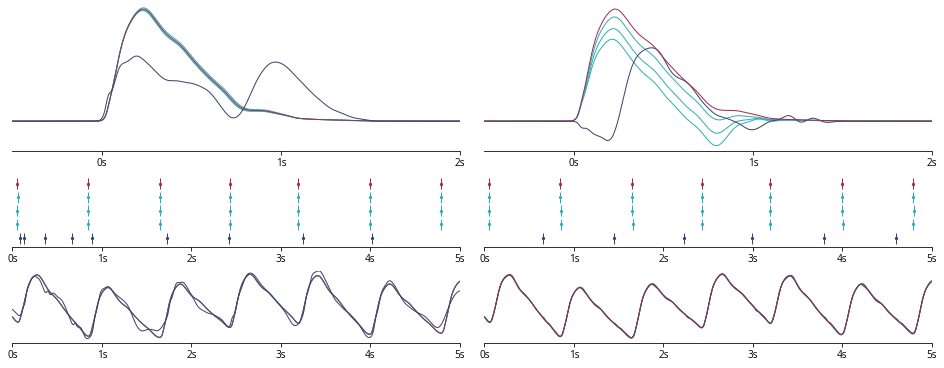

In [65]:
idx = '0015'

time_relax_plots = [
    ('bpd', cp[1], 'original', 0),
    ('bpd_RTA_RSX', cp[3], 'A', -1),
    ('bpd_RTB_RSX', cp[3], 'B', -1),
    ('bpd_RTC_RSX', cp[3], 'C', -1),
    ('bpd_RTZ_RSX', cp[0], 'Z', 1),
]

shape_relax_plots = [
    ('bpd', cp[1], 'original', 0),
    ('bpd_RTX_RSA', cp[3], 'A', -1),
    ('bpd_RTX_RSB', cp[3], 'B', -1),
    ('bpd_RTX_RSC', cp[3], 'C', -1),
    ('bpd_RTX_RSZ', cp[0], 'Z', -1),
]

fig = plt.figure(figsize=(13,5), layout='constrained')
gs = GridSpec(3,2, figure=fig,
            height_ratios=np.array([2,1,1]),
            width_ratios=[1,1],
            hspace=0.03, wspace=0.03)

t_h = np.linspace(-0.5, 2, 501)

fig.add_subplot(gs[0,0], clip_on=False)
for method, color, label, zorder in time_relax_plots:
    with open(exp_dir/idx/f'{idx}_soln_{method}.pkl', 'rb') as f:
        soln = pickle.load(f) 
    _, h = models.evaluate(t_h, z=[0], w=soln['w'], f_h=soln['f_h'], g=soln['g'], a=soln['a'])
    plt.plot(t_h, h, c=color, label=label, zorder=zorder)
plt.yticks([])
plt.xticks([0, 1, 2], ['0s', '1s', '2s'])
plt.ylim(-0.7, 2.7)

fig.add_subplot(gs[0,1], clip_on=False)
for method, color, label, zorder in shape_relax_plots:
    with open(exp_dir/idx/f'{idx}_soln_{method}.pkl', 'rb') as f:
        soln = pickle.load(f) 
    _, h = models.evaluate(t_h, z=[0], w=soln['w'], f_h=soln['f_h'], g=soln['g'], a=soln['a'])
    plt.plot(t_h, h, c=color, label=label, zorder=zorder)
plt.yticks([])
plt.xticks([0, 1, 2], ['0s', '1s', '2s'])
plt.ylim(-0.7, 2.7)

t_plot = np.linspace(6, 11, 601)

fig.add_subplot(gs[1,0], clip_on=False)
for i, (method, color, label, zorder) in enumerate(time_relax_plots):
    with open(exp_dir/idx/f'{idx}_soln_{method}.pkl', 'rb') as f:
        soln = pickle.load(f)
    plt.vlines(soln['z'], -i-0.1, -i-1+0.1, lw=1, color=color, zorder=zorder)
    plt.scatter(soln['z'], np.full_like(soln['z'], -i-0.5), c=color, s=5)
plt.yticks([])
plt.xticks([6, 7, 8, 9, 10, 11], ['0s', '1s', '2s', '3s', '4s', '5s'])
plt.xlim(t_plot[0], t_plot[-1])

fig.add_subplot(gs[1,1], clip_on=False)
for i, (method, color, label, zorder) in enumerate(shape_relax_plots):
    with open(exp_dir/idx/f'{idx}_soln_{method}.pkl', 'rb') as f:
        soln = pickle.load(f)
    plt.vlines(soln['z'], -i-0.1, -i-1+0.1, lw=1, color=color, zorder=zorder)
    plt.scatter(soln['z'], np.full_like(soln['z'], -i-0.5), c=color, s=5)
plt.yticks([])
plt.xticks([6, 7, 8, 9, 10, 11], ['0s', '1s', '2s', '3s', '4s', '5s'])
plt.xlim(t_plot[0], t_plot[-1])

fig.add_subplot(gs[2,0], clip_on=False)
for method, color, label, zorder in time_relax_plots:
    with open(exp_dir/idx/f'{idx}_soln_{method}.pkl', 'rb') as f:
        soln = pickle.load(f)
    _, y_bar_ab = models.evaluate(t_plot, z=soln['z'], w=soln['w'], f_h=soln['f_h'], g=soln['g'],
                                  a=soln['a'], b=soln['b'], f_b=soln['f_b'])
    plt.plot(t_plot, y_bar_ab, c=color, label=label, zorder=zorder)
plt.yticks([])
plt.xticks([6, 7, 8, 9, 10, 11], ['0s', '1s', '2s', '3s', '4s', '5s'])
plt.ylim(-2, 1.5) 

fig.add_subplot(gs[2,1], clip_on=False)
for method, color, label, zorder in shape_relax_plots:
    with open(exp_dir/idx/f'{idx}_soln_{method}.pkl', 'rb') as f:
        soln = pickle.load(f)
    _, y_bar_ab = models.evaluate(t_plot, z=soln['z'], w=soln['w'], f_h=soln['f_h'], g=soln['g'],
                                  a=soln['a'], b=soln['b'], f_b=soln['f_b'])
    plt.plot(t_plot, y_bar_ab, c=color, label=label, zorder=zorder)
plt.yticks([])
plt.xticks([6, 7, 8, 9, 10, 11], ['0s', '1s', '2s', '3s', '4s', '5s'])
plt.ylim(-2, 1.5) 

sns.despine(left=True)

plt.savefig(f'{FIG}.pdf', transparent=True)
plt.savefig(f'{FIG}.png', transparent=True, dpi=200)
plt.show()
